# People Analytics: Employee Job Satisfaction Analysis

**Data Analyst Bootcamp – Dibimbing**

## Objective

Menganalisis data employee survey untuk mengidentifikasi faktor-faktor yang berkaitan dengan job satisfaction dan menghasilkan insight serta strategic recommendations berbasis data.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Library berhasil diimport!")

Library berhasil diimport!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving assignment_employee_survey.csv to assignment_employee_survey (1).csv


In [ ]:
df = pd.read_csv('assignment_employee_survey.csv')

df.head()

,emp_id,gender,age,marital_status,job_level,experience,dept,emp_type,wlb,work_env,physical_activity_hours,workload,stress,sleep_hours,commute_mode,commute_distance,num_companies,team_size,num_reports,edu_level,have_ot,training_hours_per_year,job_satisfaction
0,6,Male,32,Married,Mid,7,IT,Full-Time,1,1,2.5,2,1,7.6,Car,20,3,12,0,Bachelor,True,33.5,5
1,11,Female,34,Married,Mid,12,Finance,Full-Time,1,1,1.8,2,2,7.9,Car,15,4,11,0,Bachelor,False,36.0,5
2,33,Female,23,Single,Intern/Fresher,1,Marketing,Full-Time,2,4,2.1,5,4,6.5,Motorbike,17,0,30,0,Bachelor,True,10.5,5
3,20,Female,29,Married,Junior,6,IT,Contract,2,2,1.9,3,1,7.5,Public Transport,13,2,9,0,Bachelor,True,23.0,5
4,45,Female,33,Married,Mid,10,Operations,Part-Time,2,3,1.4,4,2,6.2,Car,8,3,13,0,Bachelor,False,35.0,5


In [ ]:
styled_df = df.head().style \
    .set_caption("Preview Data Employee Survey") \
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2c3e50'),
            ('color', 'white'),
            ('font-weight', 'bold'),
            ('text-align', 'center'),
            ('padding', '10px 15px'),
            ('font-family', 'Arial, sans-serif')
        ]},
        {'selector': 'td', 'props': [
            ('text-align', 'center'),
            ('padding', '8px 12px'),
            ('font-family', 'Arial, sans-serif')
        ]},
        {'selector': 'tr:nth-of-type(even)', 'props': [('background-color', '#f8f9fa')]},
        {'selector': 'tr:hover', 'props': [('background-color', '#e2e6ea')]}
    ]) \
    .hide(axis='index')  # Hapus baris ini jika tetap ingin menampilkan indeks angka 0, 1, 2...

styled_df

emp_id,gender,age,marital_status,job_level,experience,dept,emp_type,wlb,work_env,physical_activity_hours,workload,stress,sleep_hours,commute_mode,commute_distance,num_companies,team_size,num_reports,edu_level,have_ot,training_hours_per_year,job_satisfaction
6,Male,32,Married,Mid,7,IT,Full-Time,1,1,2.500000,2,1,7.600000,Car,20,3,12,0,Bachelor,True,33.500000,5
11,Female,34,Married,Mid,12,Finance,Full-Time,1,1,1.800000,2,2,7.900000,Car,15,4,11,0,Bachelor,False,36.000000,5
33,Female,23,Single,Intern/Fresher,1,Marketing,Full-Time,2,4,2.100000,5,4,6.500000,Motorbike,17,0,30,0,Bachelor,True,10.500000,5
20,Female,29,Married,Junior,6,IT,Contract,2,2,1.900000,3,1,7.500000,Public Transport,13,2,9,0,Bachelor,True,23.000000,5
45,Female,33,Married,Mid,10,Operations,Part-Time,2,3,1.400000,4,2,6.200000,Car,8,3,13,0,Bachelor,False,35.000000,5


In [ ]:
df.shape

(2766, 23)

In [ ]:
df.columns

Index(['emp_id', 'gender', 'age', 'marital_status', 'job_level', 'experience',
       'dept', 'emp_type', 'wlb', 'work_env', 'physical_activity_hours',
       'workload', 'stress', 'sleep_hours', 'commute_mode', 'commute_distance',
       'num_companies', 'team_size', 'num_reports', 'edu_level', 'have_ot',
       'training_hours_per_year', 'job_satisfaction'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2766 entries, 0 to 2765
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   emp_id                   2766 non-null   int64  
 1   gender                   2766 non-null   object 
 2   age                      2766 non-null   int64  
 3   marital_status           2766 non-null   object 
 4   job_level                2766 non-null   object 
 5   experience               2766 non-null   int64  
 6   dept                     2766 non-null   object 
 7   emp_type                 2766 non-null   object 
 8   wlb                      2766 non-null   int64  
 9   work_env                 2766 non-null   int64  
 10  physical_activity_hours  2766 non-null   float64
 11  workload                 2766 non-null   int64  
 12  stress                   2766 non-null   int64  
 13  sleep_hours              2766 non-null   float64
 14  commute_mode            

In [ ]:
missing = df.isnull().sum()

missing

,0
emp_id,0
gender,0
age,0
marital_status,0
job_level,0
experience,0
dept,0
emp_type,0
wlb,0
work_env,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,emp_id,age,experience,wlb,work_env,physical_activity_hours,workload,stress,sleep_hours,commute_distance,num_companies,team_size,num_reports,training_hours_per_year,job_satisfaction
count,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000
mean,1516.601952,35.650759,8.989154,3.049530,3.028923,2.038250,2.979031,1.737166,7.008351,13.419740,4.223066,16.491685,2.374187,37.220535,3.380694
std,873.996466,10.175719,7.003013,1.448103,1.417494,0.966535,1.405335,1.065303,1.003736,8.344388,3.377586,6.638354,3.055823,13.540622,1.267785
min,1.000000,22.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,4.000000,1.000000,0.000000,5.000000,0.000000,10.000000,1.000000
25%,764.500000,27.000000,3.000000,2.000000,2.000000,1.400000,2.000000,1.000000,6.300000,6.000000,1.000000,11.000000,0.000000,23.500000,3.000000
50%,1515.500000,34.000000,8.000000,3.000000,3.000000,2.100000,3.000000,1.000000,7.000000,13.000000,4.000000,16.000000,0.000000,39.500000,4.000000
75%,2271.750000,43.000000,14.000000,4.000000,4.000000,2.700000,4.000000,2.000000,7.700000,20.000000,7.000000,22.000000,5.000000,46.500000,4.000000
max,3025.000000,60.000000,29.000000,5.000000,5.000000,5.000000,5.000000,5.000000,10.000000,29.000000,12.000000,30.000000,9.000000,64.500000,5.000000


In [ ]:
df.describe(include='all')

,emp_id,gender,age,marital_status,job_level,experience,dept,emp_type,wlb,work_env,physical_activity_hours,workload,stress,sleep_hours,commute_mode,commute_distance,num_companies,team_size,num_reports,edu_level,have_ot,training_hours_per_year,job_satisfaction
count,2766.000000,2766,2766.000000,2766,2766,2766.000000,2766,2766,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766.000000,2766,2766.000000,2766.000000,2766.000000,2766.000000,2766,2766,2766.000000,2766.000000
unique,NaN,2,NaN,3,5,NaN,8,3,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,4,2,NaN,NaN
top,NaN,Male,NaN,Married,Senior,NaN,IT,Full-Time,NaN,NaN,NaN,NaN,NaN,NaN,Car,NaN,NaN,NaN,NaN,Bachelor,False,NaN,NaN
freq,NaN,1526,NaN,1397,979,NaN,723,1897,NaN,NaN,NaN,NaN,NaN,NaN,998,NaN,NaN,NaN,NaN,2107,1900,NaN,NaN
mean,1516.601952,NaN,35.650759,NaN,NaN,8.989154,NaN,NaN,3.049530,3.028923,2.038250,2.979031,1.737166,7.008351,NaN,13.419740,4.223066,16.491685,2.374187,NaN,NaN,37.220535,3.380694
std,873.996466,NaN,10.175719,NaN,NaN,7.003013,NaN,NaN,1.448103,1.417494,0.966535,1.405335,1.065303,1.003736,NaN,8.344388,3.377586,6.638354,3.055823,NaN,NaN,13.540622,1.267785
min,1.000000,NaN,22.000000,NaN,NaN,0.000000,NaN,NaN,1.000000,1.000000,0.000000,1.000000,1.000000,4.000000,NaN,1.000000,0.000000,5.000000,0.000000,NaN,NaN,10.000000,1.000000
25%,764.500000,NaN,27.000000,NaN,NaN,3.000000,NaN,NaN,2.000000,2.000000,1.400000,2.000000,1.000000,6.300000,NaN,6.000000,1.000000,11.000000,0.000000,NaN,NaN,23.500000,3.000000
50%,1515.500000,NaN,34.000000,NaN,NaN,8.000000,NaN,NaN,3.000000,3.000000,2.100000,3.000000,1.000000,7.000000,NaN,13.000000,4.000000,16.000000,0.000000,NaN,NaN,39.500000,4.000000
75%,2271.750000,NaN,43.000000,NaN,NaN,14.000000,NaN,NaN,4.000000,4.000000,2.700000,4.000000,2.000000,7.700000,NaN,20.000000,7.000000,22.000000,5.000000,NaN,NaN,46.500000,4.000000


**DATA CLEANING & VALIDATION**

In [ ]:
###Cek Missing Values
missing = df.isnull().sum()

missing[missing > 0]

,0


In [ ]:
### Cek Duplicate
df.duplicated().sum()

np.int64(0)

In [ ]:
##CEK NILAI UNIK VARIABLE KATEGORIKAL
categorical_cols = [
    'gender',
    'marital_status',
    'job_level',
    'dept',
    'emp_type',
    'commute_mode',
    'edu_level'
]

for col in categorical_cols:
    print(f"\n=== {col} ===")
    print(df[col].value_counts())


=== gender ===
gender
Male      1526
Female    1240
Name: count, dtype: int64

=== marital_status ===
marital_status
Married     1397
Single      1180
Divorced     189
Name: count, dtype: int64

=== job_level ===
job_level
Senior            979
Mid               696
Junior            557
Lead              350
Intern/Fresher    184
Name: count, dtype: int64

=== dept ===
dept
IT                  723
Finance             565
Operations          410
Marketing           292
Sales               260
Legal               249
Customer Service    137
HR                  130
Name: count, dtype: int64

=== emp_type ===
emp_type
Full-Time    1897
Part-Time     579
Contract      290
Name: count, dtype: int64

=== commute_mode ===
commute_mode
Car                 998
Public Transport    804
Bike                400
Motorbike           289
Walk                275
Name: count, dtype: int64

=== edu_level ===
edu_level
Bachelor       2107
Master          346
High School     227
PhD              86
Name: 

In [ ]:
#### CEK RANGE VARIABLE NUMERIK
numeric_cols = [
    'age',
    'experience',
    'wlb',
    'work_env',
    'physical_activity_hours',
    'workload',
    'stress',
    'sleep_hours',
    'commute_distance',
    'num_companies',
    'team_size',
    'num_reports',
    'training_hours_per_year',
    'job_satisfaction'
]

for col in numeric_cols:
    print(
        f"{col}: "
        f"min={df[col].min()}, "
        f"max={df[col].max()}"
    )

age: min=22, max=60
experience: min=0, max=29
wlb: min=1, max=5
work_env: min=1, max=5
physical_activity_hours: min=0.0, max=5.0
workload: min=1, max=5
stress: min=1, max=5
sleep_hours: min=4.0, max=10.0
commute_distance: min=1, max=29
num_companies: min=0, max=12
team_size: min=5, max=30
num_reports: min=0, max=9
training_hours_per_year: min=10.0, max=64.5
job_satisfaction: min=1, max=5


In [ ]:
### CEK  LOGICAL VALIDATION
print("Age < 18:", (df['age'] < 18).sum())
print("Experience > Age:", (df['experience'] > df['age']).sum())
print("Sleep Hours <= 0:", (df['sleep_hours'] <= 0).sum())
print("Commute Distance < 0:", (df['commute_distance'] < 0).sum())

Age < 18: 0
Experience > Age: 0
Sleep Hours <= 0: 0
Commute Distance < 0: 0


In [ ]:
######CEK OUTLIER
outlier_cols = [
    'age',
    'experience',
    'physical_activity_hours',
    'sleep_hours',
    'commute_distance',
    'num_companies',
    'team_size',
    'num_reports',
    'training_hours_per_year'
]

In [ ]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outlier")

age: 0 outlier
experience: 0 outlier
physical_activity_hours: 6 outlier
sleep_hours: 13 outlier
commute_distance: 0 outlier
num_companies: 0 outlier
team_size: 0 outlier
num_reports: 0 outlier
training_hours_per_year: 0 outlier


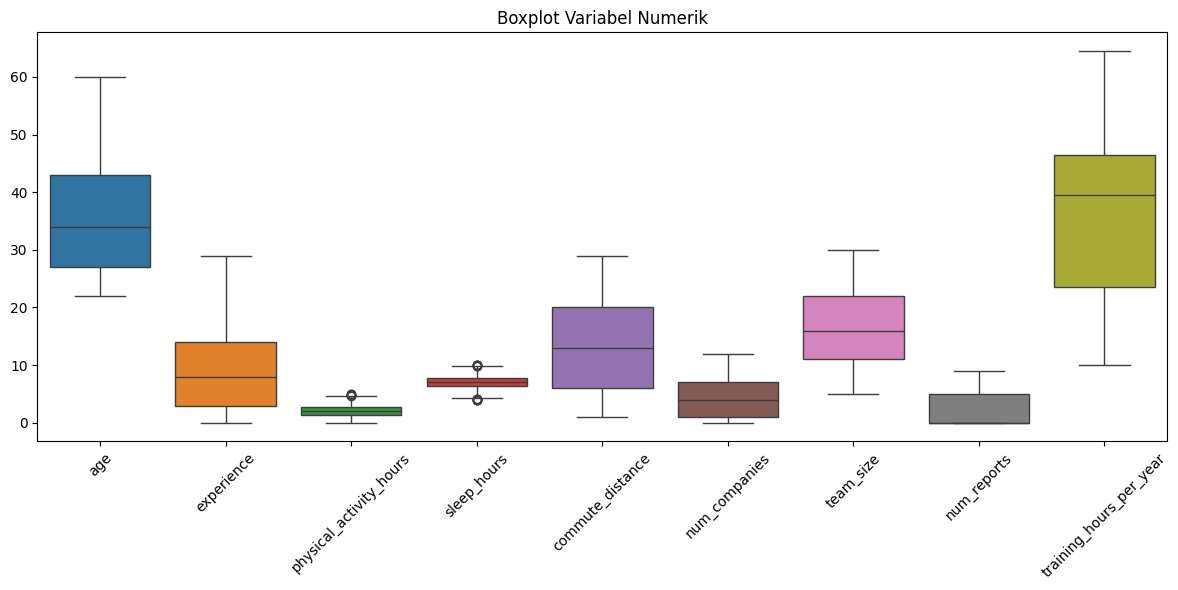

In [ ]:
####Visualisasi  Outliernya
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[outlier_cols])

plt.xticks(rotation=45)
plt.title('Boxplot Variabel Numerik')
plt.tight_layout()
plt.show()

In [ ]:
### Visualisasi Job Satisfaction
print(df['job_satisfaction'].value_counts().sort_index())

job_satisfaction
1     388
2     254
3     519
4    1127
5     478
Name: count, dtype: int64


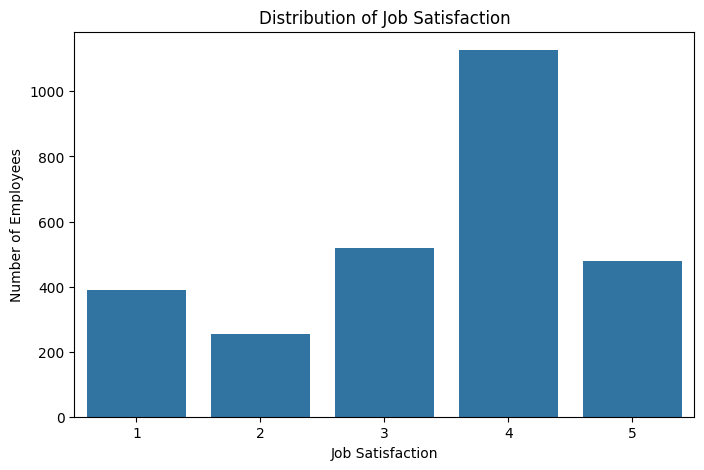

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='job_satisfaction'
)

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction')
plt.ylabel('Number of Employees')

plt.show()

In [ ]:
### CEK RATA_ RATA JOB SATISFACTION
mean_satisfaction = df['job_satisfaction'].mean()

print("Average Job Satisfaction:",
      round(mean_satisfaction, 2))

Average Job Satisfaction: 3.38


In [ ]:
### Simpan dataset CLean
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Clean dataset:", df_clean.shape)

Original dataset: (2766, 23)
Clean dataset: (2766, 23)


## 1. Data Understanding

Dataset yang digunakan adalah Employee Survey dengan 2.766 observasi dan 23 variabel.

Variabel yang dianalisis mencakup karakteristik karyawan, kondisi pekerjaan, workload, stress, work-life balance, work environment, dan job satisfaction.

Variabel target dalam analisis adalah `job_satisfaction`.

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2766
Number of columns: 23


**EXPLORATORY DATA**

In [ ]:
####Distribusi Job Satisfaction

####Pertama kita lihat kondisi kepuasan karyawan secara keseluruhan.
satisfaction_counts = df_clean['job_satisfaction'].value_counts().sort_index()

print(satisfaction_counts)

job_satisfaction
1     388
2     254
3     519
4    1127
5     478
Name: count, dtype: int64


In [ ]:
###Hitung persentaasinya
satisfaction_pct = (
    df_clean['job_satisfaction']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(satisfaction_pct.round(1))

job_satisfaction
1    14.0
2     9.2
3    18.8
4    40.7
5    17.3
Name: proportion, dtype: float64


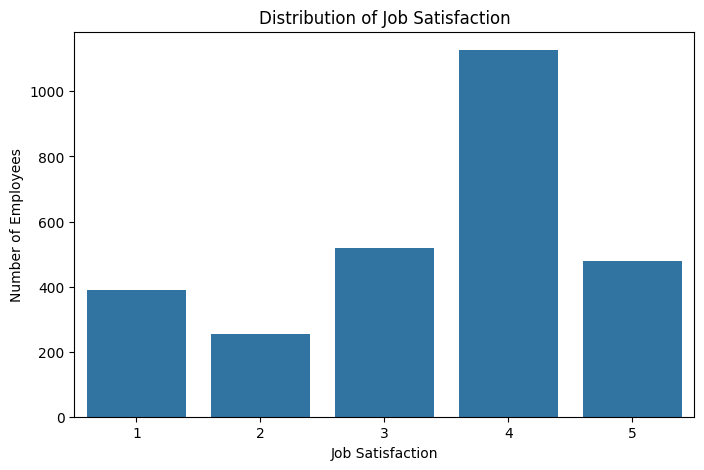

In [ ]:
###visualisasinya
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x='job_satisfaction'
)

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction')
plt.ylabel('Number of Employees')

plt.show()

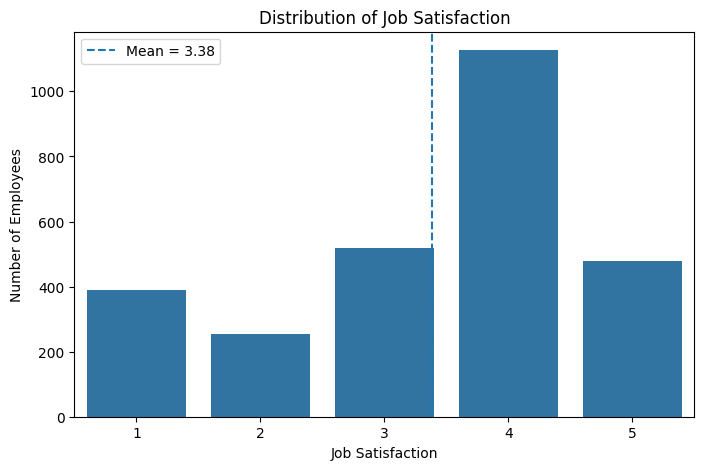

In [ ]:
####untuk garis RATA RATAnya
mean_satisfaction = df_clean['job_satisfaction'].mean()

plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x='job_satisfaction'
)

plt.axvline(
    mean_satisfaction - 1,
    linestyle='--',
    label=f'Mean = {mean_satisfaction:.2f}'
)

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction')
plt.ylabel('Number of Employees')
plt.legend()

plt.show()

In [ ]:
####untuk Korelasi Variabel Numerik
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

correlation = (
    df_clean[numeric_cols]
    .corr()['job_satisfaction']
    .sort_values(ascending=False)
)

print(correlation)

job_satisfaction           1.000000
wlb                        0.256853
work_env                   0.244227
sleep_hours                0.177377
emp_id                     0.078075
commute_distance           0.003727
team_size                  0.002718
num_companies             -0.008437
training_hours_per_year   -0.009717
age                       -0.011165
physical_activity_hours   -0.012094
experience                -0.013914
num_reports               -0.027634
stress                    -0.212416
workload                  -0.257175
Name: job_satisfaction, dtype: float64


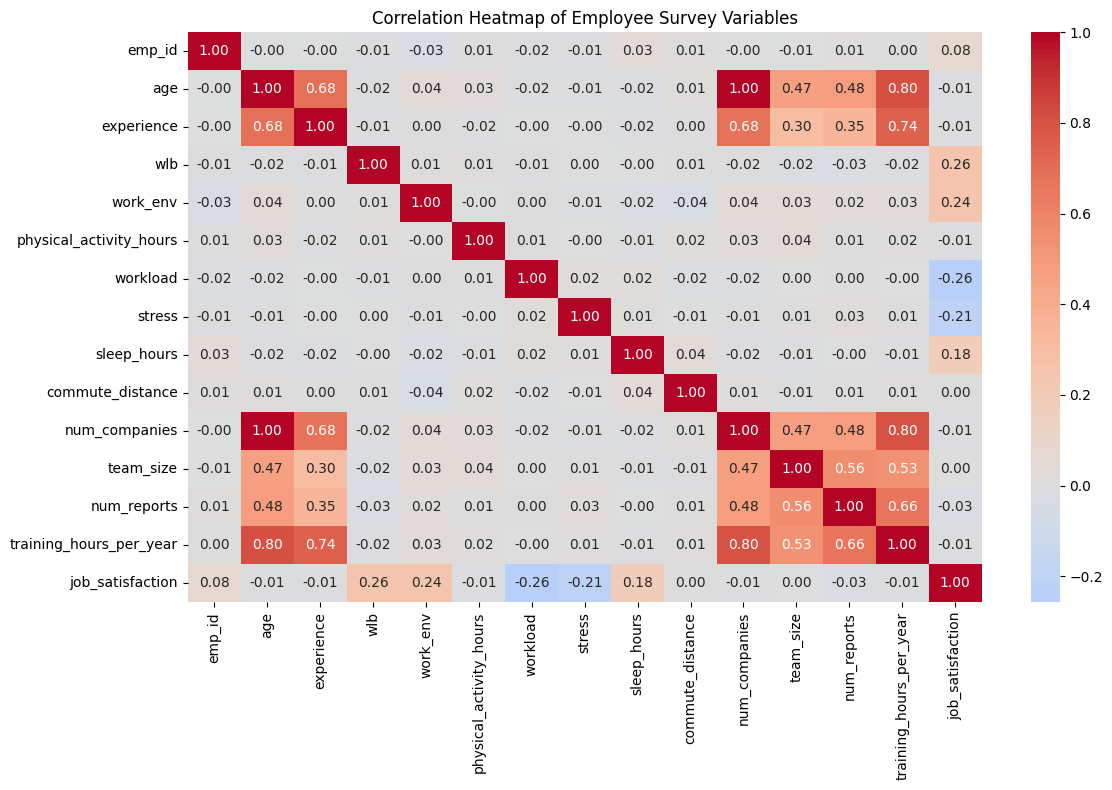

In [ ]:
####Correlation Heatmap
plt.figure(figsize=(12,8))

corr_matrix = df_clean[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Employee Survey Variables')

plt.tight_layout()
plt.show()

In [ ]:
#####Faktor #1 — Work-Life Balance
wlb_analysis = (
    df_clean
    .groupby('wlb')['job_satisfaction']
    .agg(['count', 'mean'])
    .reset_index()
)

wlb_analysis

,wlb,count,mean
0,1,575,2.906087
1,2,502,3.133466
2,3,507,3.402367
3,4,575,3.620870
4,5,607,3.789127


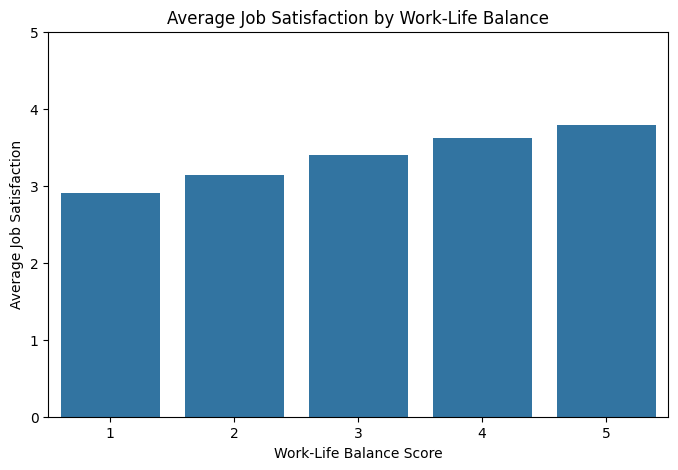

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=wlb_analysis,
    x='wlb',
    y='mean'
)

plt.title('Average Job Satisfaction by Work-Life Balance')
plt.xlabel('Work-Life Balance Score')
plt.ylabel('Average Job Satisfaction')

plt.ylim(0,5)

plt.show()

Kalau pola tersebut terlihat konsisten, kita memiliki bukti deskriptif bahwa Work-Life Balance memiliki hubungan positif dengan Job Satisfaction.

In [ ]:
#### FAKTOR #2_WORK ENVIRONMENT
workenv_analysis = (
    df_clean
    .groupby('work_env')['job_satisfaction']
    .agg(['count', 'mean'])
    .reset_index()
)

workenv_analysis

,work_env,count,mean
0,1,532,2.906015
1,2,554,3.191336
2,3,571,3.362522
3,4,520,3.634615
4,5,589,3.780985


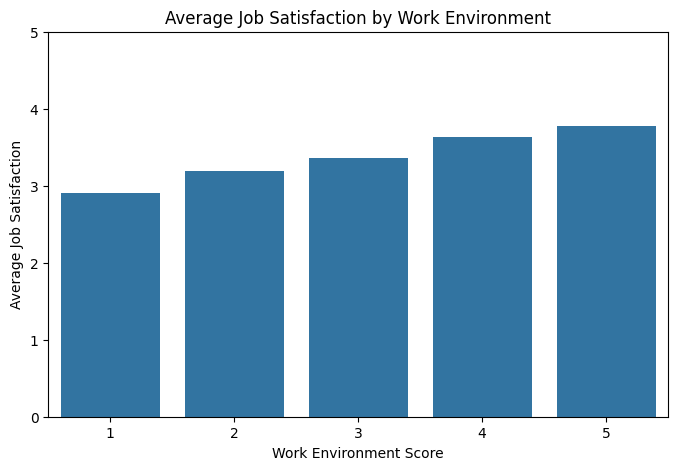

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=workenv_analysis,
    x='work_env',
    y='mean'
)

plt.title('Average Job Satisfaction by Work Environment')
plt.xlabel('Work Environment Score')
plt.ylabel('Average Job Satisfaction')

plt.ylim(0,5)

plt.show()

Tujuannya melihat apakah kualitas lingkungan kerja yang lebih tinggi diikuti rata-rata satisfaction yang lebih tinggi.

*   List item
*   List item



In [ ]:
##FAKTOR ##3__WORKLOAD
workload_analysis = (
    df_clean
    .groupby('workload')['job_satisfaction']
    .agg(['count', 'mean'])
    .reset_index()
)

workload_analysis

,workload,count,mean
0,1,559,3.774597
1,2,560,3.689286
2,3,550,3.363636
3,4,574,3.182927
4,5,523,2.864245


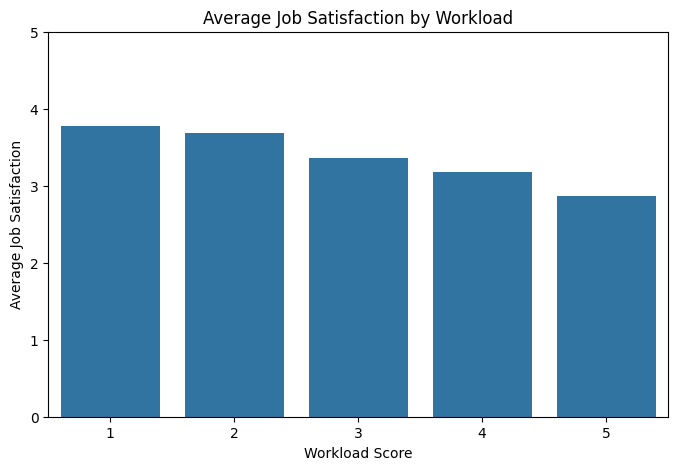

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=workload_analysis,
    x='workload',
    y='mean'
)

plt.title('Average Job Satisfaction by Workload')
plt.xlabel('Workload Score')
plt.ylabel('Average Job Satisfaction')

plt.ylim(0,5)

plt.show()

Jika grafik menunjukkan kecenderungan menurun:

semakin tinggi workload → rata-rata Job Satisfaction cenderung menurun.

In [ ]:
##Faktor #4 — Stress
stress_analysis = (
    df_clean
    .groupby('stress')['job_satisfaction']
    .agg(['count', 'mean'])
    .reset_index()
)

stress_analysis

,stress,count,mean
0,1,1656,3.557971
1,2,483,3.380952
2,3,395,3.012658
3,4,162,2.820988
4,5,70,2.557143


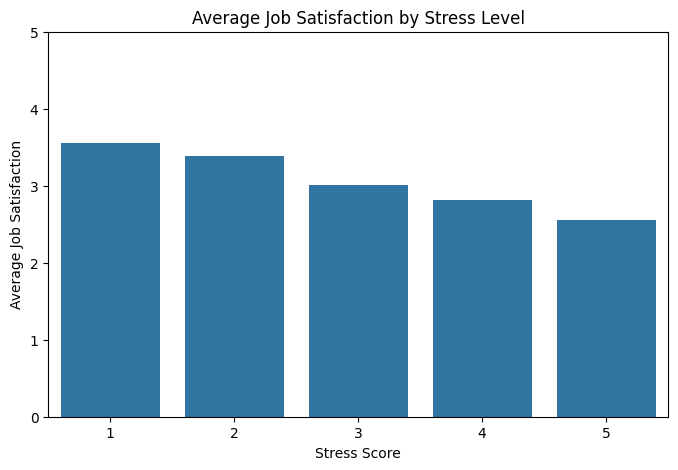

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=stress_analysis,
    x='stress',
    y='mean'
)

plt.title('Average Job Satisfaction by Stress Level')
plt.xlabel('Stress Score')
plt.ylabel('Average Job Satisfaction')

plt.ylim(0,5)

plt.show()

Kalau pola grafik turun, maka:

tingkat stress yang lebih tinggi cenderung berkaitan dengan Job Satisfaction yang lebih rendah.

In [ ]:
##Faktor #5 — Overtime
ot_analysis = (
    df_clean
    .groupby('have_ot')['job_satisfaction']
    .agg(['count', 'mean'])
    .reset_index()
)

ot_analysis

,have_ot,count,mean
0,False,1900,3.512632
1,True,866,3.091224


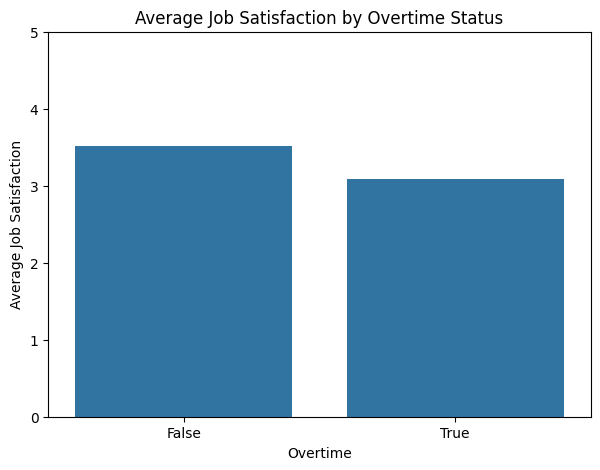

In [ ]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=ot_analysis,
    x='have_ot',
    y='mean'
)

plt.title('Average Job Satisfaction by Overtime Status')
plt.xlabel('Overtime')
plt.ylabel('Average Job Satisfaction')

plt.ylim(0,5)

plt.show()

Karyawan yang memiliki overtime menunjukkan rata-rata Job Satisfaction yang lebih rendah dibandingkan karyawan tanpa overtime

In [ ]:
####Analisis Department
dept_analysis = (
    df_clean
    .groupby('dept')['job_satisfaction']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
    .reset_index()
)

dept_analysis

,dept,count,mean
0,Sales,260,3.476923
1,Operations,410,3.460976
2,Finance,565,3.423009
3,HR,130,3.400000
4,Legal,249,3.381526
5,Marketing,292,3.342466
6,Customer Service,137,3.335766
7,IT,723,3.287690


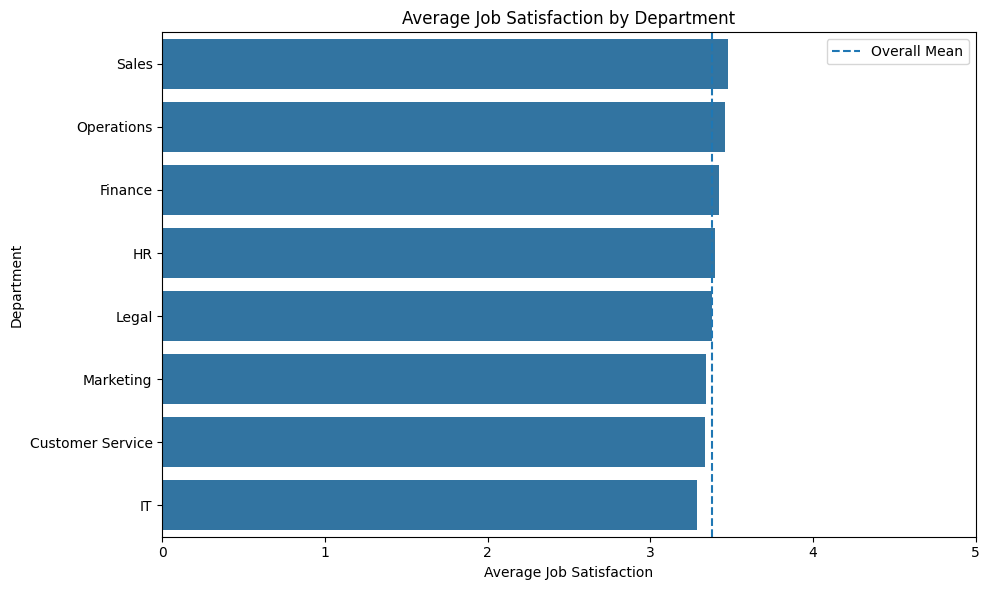

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=dept_analysis,
    x='mean',
    y='dept'
)

plt.axvline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Average Job Satisfaction by Department')
plt.xlabel('Average Job Satisfaction')
plt.ylabel('Department')

plt.xlim(0,5)
plt.legend()

plt.tight_layout()
plt.show()

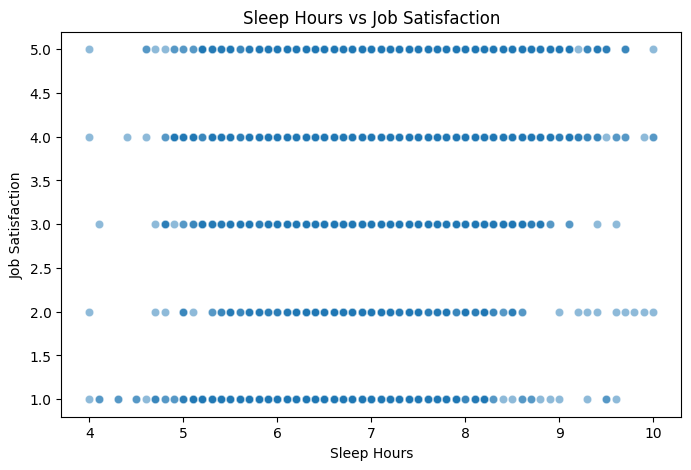

In [ ]:
###Analisis Sleep Hours
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_clean,
    x='sleep_hours',
    y='job_satisfaction',
    alpha=0.5
)

plt.title('Sleep Hours vs Job Satisfaction')
plt.xlabel('Sleep Hours')
plt.ylabel('Job Satisfaction')

plt.show()

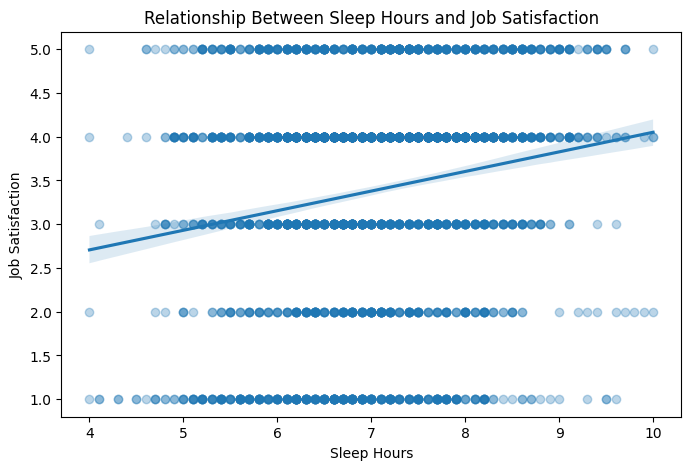

In [ ]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df_clean,
    x='sleep_hours',
    y='job_satisfaction',
    scatter_kws={'alpha': 0.3}
)

plt.title('Relationship Between Sleep Hours and Job Satisfaction')
plt.xlabel('Sleep Hours')
plt.ylabel('Job Satisfaction')

plt.show()

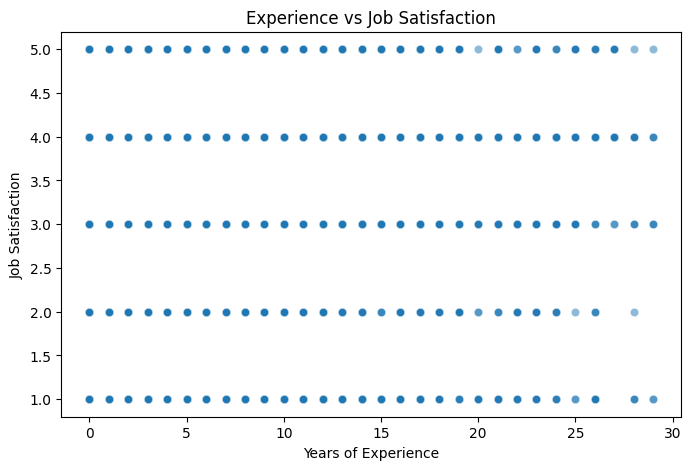

In [ ]:
##Analisis Experience
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_clean,
    x='experience',
    y='job_satisfaction',
    alpha=0.5
)

plt.title('Experience vs Job Satisfaction')
plt.xlabel('Years of Experience')
plt.ylabel('Job Satisfaction')

plt.show()

In [ ]:
###Buat Ranking Faktor Numerik
factor_corr = (
    correlation
    .drop(['job_satisfaction', 'emp_id'])
    .sort_values(key=abs, ascending=False)
)

factor_corr

,job_satisfaction
workload,-0.257175
wlb,0.256853
work_env,0.244227
stress,-0.212416
sleep_hours,0.177377
num_reports,-0.027634
experience,-0.013914
physical_activity_hours,-0.012094
age,-0.011165
training_hours_per_year,-0.009717


In [ ]:
####Analisis Work-Life Balance
wlb_analysis = (
    df_clean
    .groupby('wlb')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .reset_index()
)

wlb_analysis['average_satisfaction'] = (
    wlb_analysis['average_satisfaction'].round(2)
)

wlb_analysis

,wlb,employee_count,average_satisfaction
0,1,575,2.91
1,2,502,3.13
2,3,507,3.40
3,4,575,3.62
4,5,607,3.79


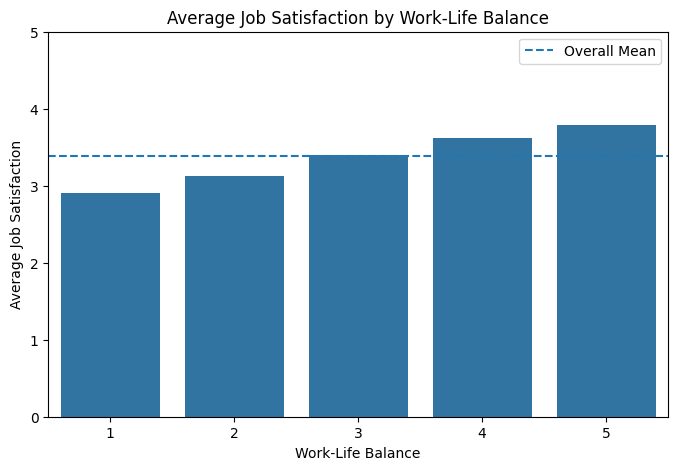

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=wlb_analysis,
    x='wlb',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Average Job Satisfaction by Work-Life Balance')
plt.xlabel('Work-Life Balance')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.show()

Semakin tinggi skor Work- Life Balance, semakin tinggi rta  rata job Satisfaction.

In [ ]:
###Analisis Work Environment
workenv_analysis = (
    df_clean
    .groupby('work_env')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .reset_index()
)

workenv_analysis['average_satisfaction'] = (
    workenv_analysis['average_satisfaction'].round(2)
)

workenv_analysis

,work_env,employee_count,average_satisfaction
0,1,532,2.91
1,2,554,3.19
2,3,571,3.36
3,4,520,3.63
4,5,589,3.78


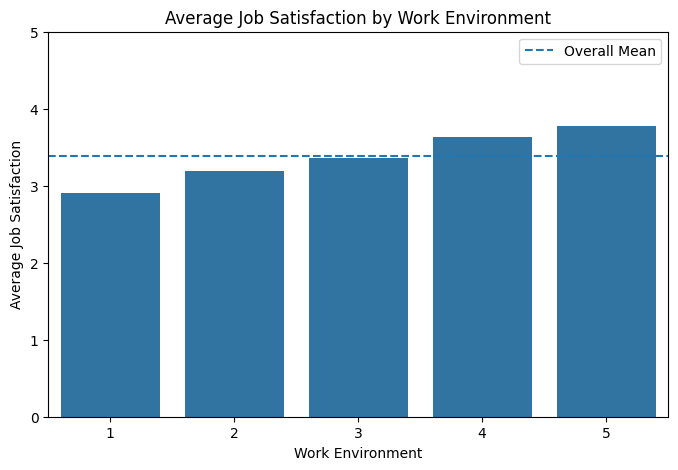

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=workenv_analysis,
    x='work_env',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Average Job Satisfaction by Work Environment')
plt.xlabel('Work Environment')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.show()

skor Work Environment yang lebih tinggi diikuti rata-rata Job Satisfaction yang lebih tinggi.

In [ ]:
####Analisis  Workload
workload_analysis = (
    df_clean
    .groupby('workload')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .reset_index()
)

workload_analysis['average_satisfaction'] = (
    workload_analysis['average_satisfaction'].round(2)
)

workload_analysis

,workload,employee_count,average_satisfaction
0,1,559,3.77
1,2,560,3.69
2,3,550,3.36
3,4,574,3.18
4,5,523,2.86


In [ ]:
#### Analisis stress
stress_analysis = (
    df_clean
    .groupby('stress')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .reset_index()
)

stress_analysis['average_satisfaction'] = (
    stress_analysis['average_satisfaction'].round(2)
)

stress_analysis

,stress,employee_count,average_satisfaction
0,1,1656,3.56
1,2,483,3.38
2,3,395,3.01
3,4,162,2.82
4,5,70,2.56


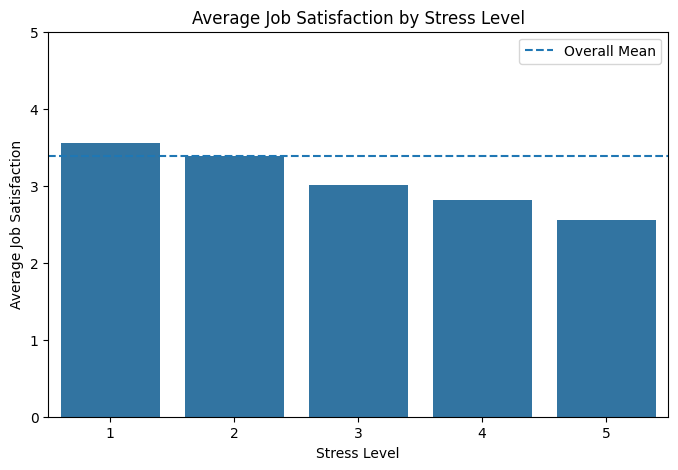

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=stress_analysis,
    x='stress',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Average Job Satisfaction by Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.show()

Ada pola penurunan yang konsisten:

semakin tinggi tingkat stress, semakin rendah rata-rata Job Satisfaction.

Perbedaannya:

Stress 1 → 3,56

vs.

Stress 5 → 2,56

Selisih:

1,00 poin.

Ini bahkan lebih besar daripada perbedaan pada WLB dan Work Environment.

In [ ]:
##Analisis Overtime
ot_analysis = (
    df_clean
    .groupby('have_ot')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .reset_index()
)

ot_analysis['average_satisfaction'] = (
    ot_analysis['average_satisfaction'].round(2)
)

ot_analysis

,have_ot,employee_count,average_satisfaction
0,False,1900,3.51
1,True,866,3.09


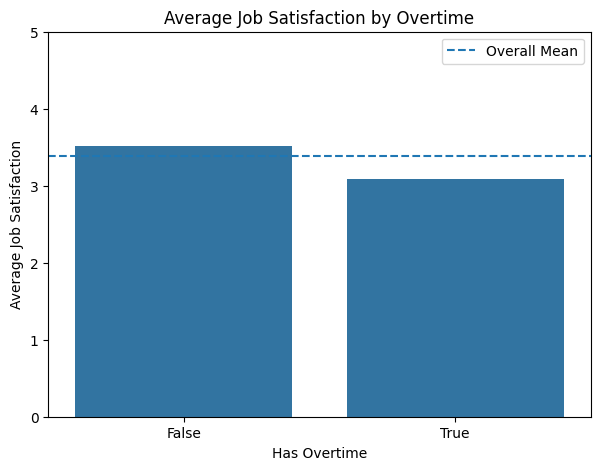

In [ ]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=ot_analysis,
    x='have_ot',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Average Job Satisfaction by Overtime')
plt.xlabel('Has Overtime')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.show()

Interpretasi

Karyawan yang memiliki overtime mempunyai rata-rata Job Satisfaction sekitar:

3,09

sementara yang tidak:

3,51.

Perbedaan:

0,42 poin.

Ini mendukung pola bahwa workload/time demand berhubungan dengan kepuasan kerja.

In [ ]:
###Analisis Department
dept_analysis = (
    df_clean
    .groupby('dept')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .sort_values('average_satisfaction', ascending=False)
    .reset_index()
)

dept_analysis['average_satisfaction'] = (
    dept_analysis['average_satisfaction'].round(2)
)

dept_analysis

,dept,employee_count,average_satisfaction
0,Sales,260,3.48
1,Operations,410,3.46
2,Finance,565,3.42
3,HR,130,3.40
4,Legal,249,3.38
5,Marketing,292,3.34
6,Customer Service,137,3.34
7,IT,723,3.29


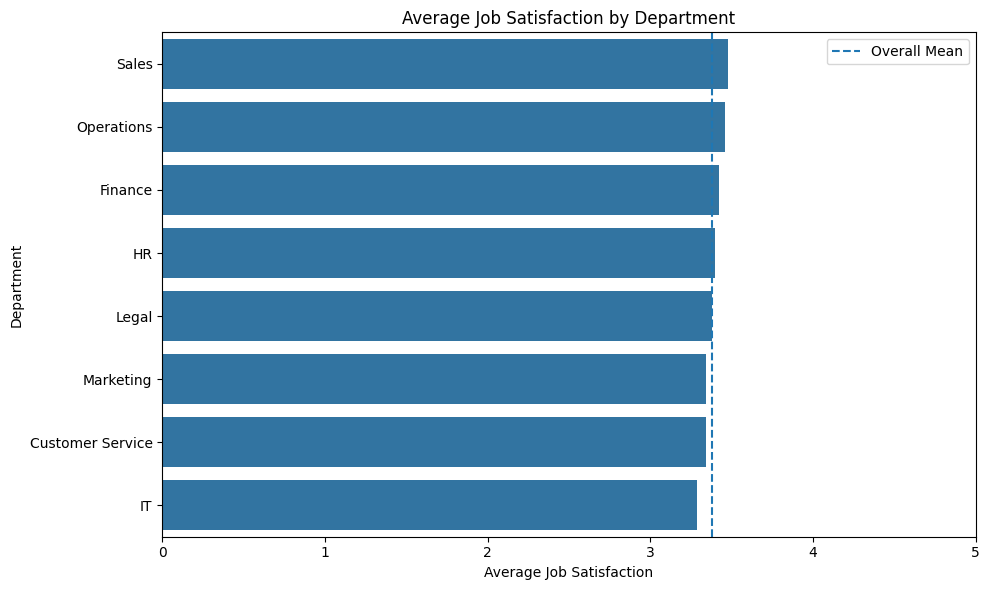

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=dept_analysis,
    x='average_satisfaction',
    y='dept'
)

plt.axvline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Average Job Satisfaction by Department')
plt.xlabel('Average Job Satisfaction')
plt.ylabel('Department')
plt.xlim(0,5)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
####Analisis Job Lavel
joblevel_analysis = (
    df_clean
    .groupby('job_level')['job_satisfaction']
    .agg(
        employee_count='count',
        average_satisfaction='mean'
    )
    .sort_values('average_satisfaction', ascending=False)
    .reset_index()
)

joblevel_analysis['average_satisfaction'] = (
    joblevel_analysis['average_satisfaction'].round(2)
)

joblevel_analysis

,job_level,employee_count,average_satisfaction
0,Mid,696,3.41
1,Senior,979,3.39
2,Junior,557,3.37
3,Intern/Fresher,184,3.36
4,Lead,350,3.31


In [ ]:
##### Tabel Ringkasan Faktor Utama
factor_summary = pd.DataFrame({
    'Factor': [
        'Work-Life Balance',
        'Workload',
        'Work Environment',
        'Stress',
        'Sleep Hours'
    ],
    'Correlation': [
        0.256853,
        -0.257175,
        0.244227,
        -0.212416,
        0.177377
    ],
    'Direction': [
        'Positive',
        'Negative',
        'Positive',
        'Negative',
        'Positive'
    ]
})

factor_summary['Abs_Correlation'] = (
    factor_summary['Correlation'].abs()
)

factor_summary = (
    factor_summary
    .sort_values('Abs_Correlation', ascending=False)
    .reset_index(drop=True)
)

factor_summary

,Factor,Correlation,Direction,Abs_Correlation
0,Workload,-0.257175,Negative,0.257175
1,Work-Life Balance,0.256853,Positive,0.256853
2,Work Environment,0.244227,Positive,0.244227
3,Stress,-0.212416,Negative,0.212416
4,Sleep Hours,0.177377,Positive,0.177377


**STATISTICAL VALIDATION**

In [ ]:
####Install/Import Statistical Library
from scipy import stats

In [ ]:
###Spearman Correlation
factors = [
    'wlb',
    'work_env',
    'workload',
    'stress',
    'sleep_hours'
]

spearman_results = []

for col in factors:
    r, p = stats.spearmanr(
        df_clean[col],
        df_clean['job_satisfaction']
    )

    spearman_results.append({
        'Factor': col,
        'Spearman Correlation': r,
        'P-value': p
    })

spearman_df = pd.DataFrame(spearman_results)

spearman_df

,Factor,Spearman Correlation,P-value
0,wlb,0.246660,1.294007e-39
1,work_env,0.245846,2.341921e-39
2,workload,-0.252256,2.068284e-41
3,stress,-0.191009,3.880744e-24
4,sleep_hours,0.168610,4.352269e-19


In [ ]:
spearman_df['Abs Correlation'] = (
    spearman_df['Spearman Correlation'].abs()
)

spearman_df = (
    spearman_df
    .sort_values('Abs Correlation', ascending=False)
    .reset_index(drop=True)
)

spearman_df

,Factor,Spearman Correlation,P-value,Abs Correlation
0,workload,-0.252256,2.068284e-41,0.252256
1,wlb,0.246660,1.294007e-39,0.246660
2,work_env,0.245846,2.341921e-39,0.245846
3,stress,-0.191009,3.880744e-24,0.191009
4,sleep_hours,0.168610,4.352269e-19,0.168610


In [ ]:
spearman_df['Significance'] = np.where(
    spearman_df['P-value'] < 0.05,
    'Significant',
    'Not Significant'
)

spearman_df

,Factor,Spearman Correlation,P-value,Abs Correlation,Significance
0,workload,-0.252256,2.068284e-41,0.252256,Significant
1,wlb,0.246660,1.294007e-39,0.246660,Significant
2,work_env,0.245846,2.341921e-39,0.245846,Significant
3,stress,-0.191009,3.880744e-24,0.191009,Significant
4,sleep_hours,0.168610,4.352269e-19,0.168610,Significant


In [ ]:
####Validasi Overtime
ot_no = df_clean.loc[
    df_clean['have_ot'] == False,
    'job_satisfaction'
]

ot_yes = df_clean.loc[
    df_clean['have_ot'] == True,
    'job_satisfaction'
]

t_stat, p_value = stats.ttest_ind(
    ot_no,
    ot_yes,
    equal_var=False
)

print("T-statistic:", round(t_stat, 3))
print("P-value:", p_value)

T-statistic: 7.893
P-value: 5.56743585149122e-15


In [ ]:
####Menampilkan perbedaanya
print(
    "Average Satisfaction - No Overtime:",
    round(ot_no.mean(), 2)
)

print(
    "Average Satisfaction - Overtime:",
    round(ot_yes.mean(), 2)
)

print(
    "Difference:",
    round(ot_no.mean() - ot_yes.mean(), 2)
)

Average Satisfaction - No Overtime: 3.51
Average Satisfaction - Overtime: 3.09
Difference: 0.42


In [ ]:
###Menganalisis Department dengan ANOVA
department_groups = [
    group['job_satisfaction'].values
    for _, group in df_clean.groupby('dept')
]

f_stat, p_value = stats.f_oneway(
    *department_groups
)

print("F-statistic:", round(f_stat, 3))
print("P-value:", p_value)

F-statistic: 1.162
P-value: 0.32136886463371034


In [ ]:
####Cek Job lavelnya
joblevel_groups = [
    group['job_satisfaction'].values
    for _, group in df_clean.groupby('job_level')
]

f_stat_level, p_value_level = stats.f_oneway(
    *joblevel_groups
)

print("F-statistic:", round(f_stat_level, 3))
print("P-value:", p_value_level)

F-statistic: 0.433
P-value: 0.7847033912706446


In [ ]:
####Tabel final analysis
final_insights = pd.DataFrame({
    'Factor': [
        'Workload',
        'Work-Life Balance',
        'Work Environment',
        'Stress',
        'Overtime'
    ],
    'Evidence': [
        'Spearman r = -0.252',
        'Spearman r = +0.247',
        'Spearman r = +0.246',
        'Spearman r = -0.191',
        'No OT = 3.51 vs OT = 3.09'
    ],
    'Insight': [
        'Higher workload is associated with lower job satisfaction',
        'Better WLB is associated with higher job satisfaction',
        'Better work environment is associated with higher job satisfaction',
        'Higher stress is associated with lower job satisfaction',
        'Employees with overtime have lower average job satisfaction'
    ]
})

final_insights

,Factor,Evidence,Insight
0,Workload,Spearman r = -0.252,Higher workload is associated with lower job s...
1,Work-Life Balance,Spearman r = +0.247,Better WLB is associated with higher job satis...
2,Work Environment,Spearman r = +0.246,Better work environment is associated with hig...
3,Stress,Spearman r = -0.191,Higher stress is associated with lower job sat...
4,Overtime,No OT = 3.51 vs OT = 3.09,Employees with overtime have lower average job...


**FINAL VISUALIZATION**

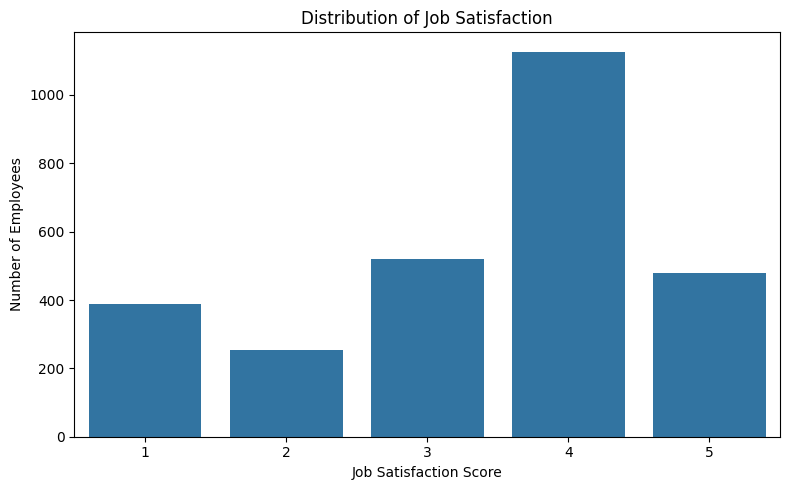

In [ ]:
###Job Satisfaction Distribution
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x='job_satisfaction'
)

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction Score')
plt.ylabel('Number of Employees')

plt.tight_layout()
plt.show()

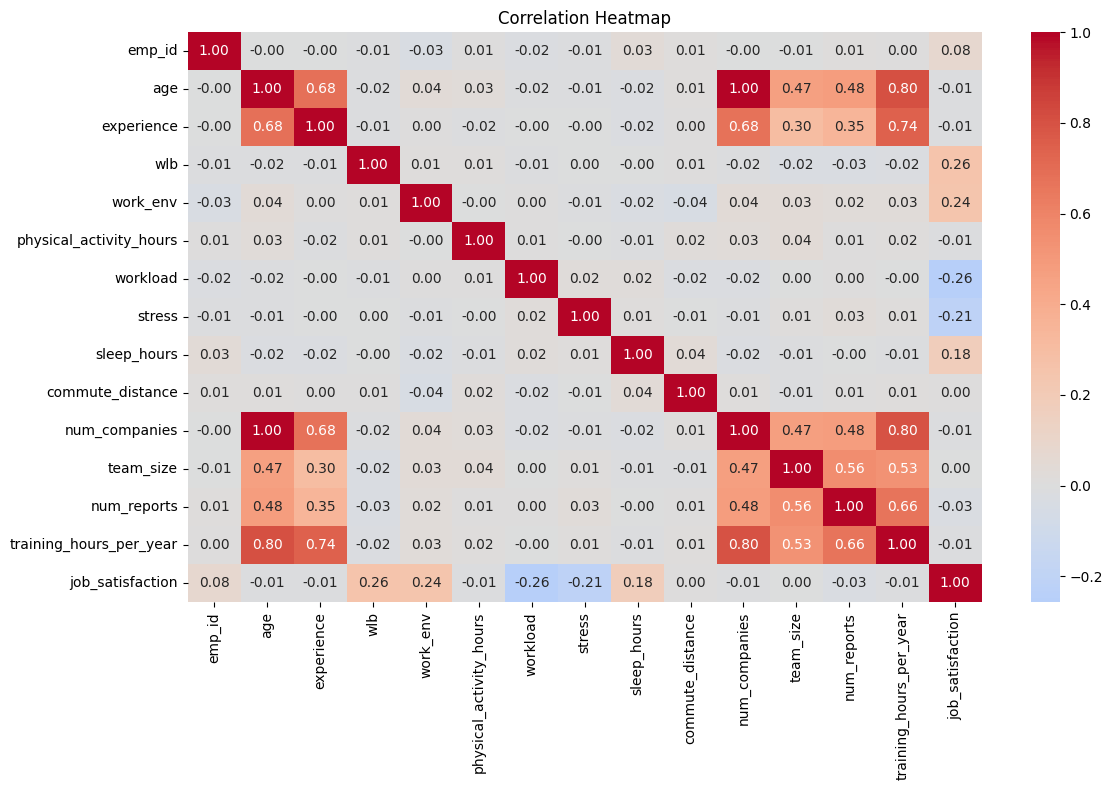

In [ ]:
###Correlation Heatmap
plt.figure(figsize=(12,8))

sns.heatmap(
    df_clean[numeric_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

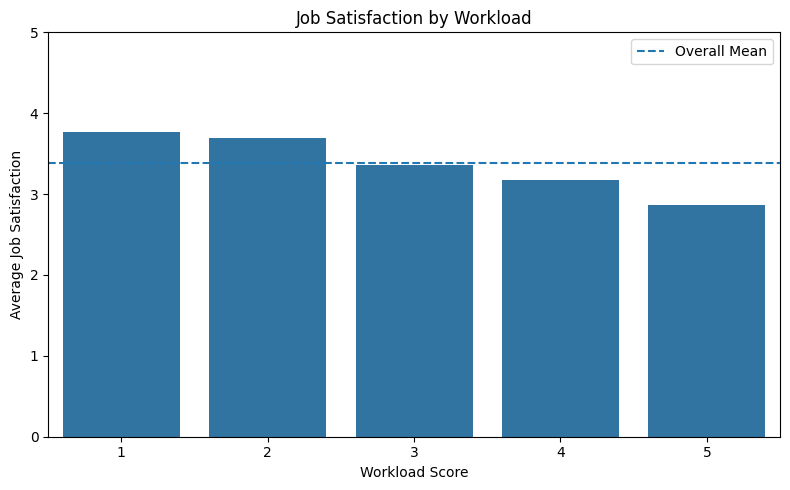

In [ ]:
###Workload
plt.figure(figsize=(8,5))

sns.barplot(
    data=workload_analysis,
    x='workload',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Job Satisfaction by Workload')
plt.xlabel('Workload Score')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.tight_layout()
plt.show()

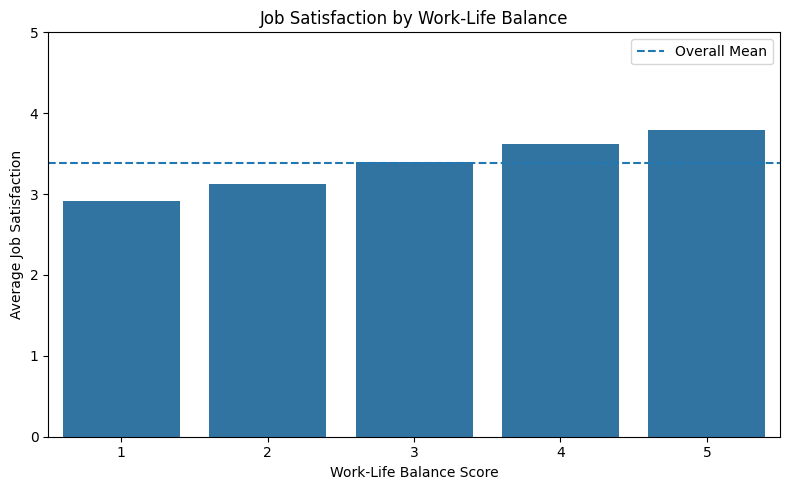

In [ ]:
##Work-Life Balance
plt.figure(figsize=(8,5))

sns.barplot(
    data=wlb_analysis,
    x='wlb',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Job Satisfaction by Work-Life Balance')
plt.xlabel('Work-Life Balance Score')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.tight_layout()
plt.show()

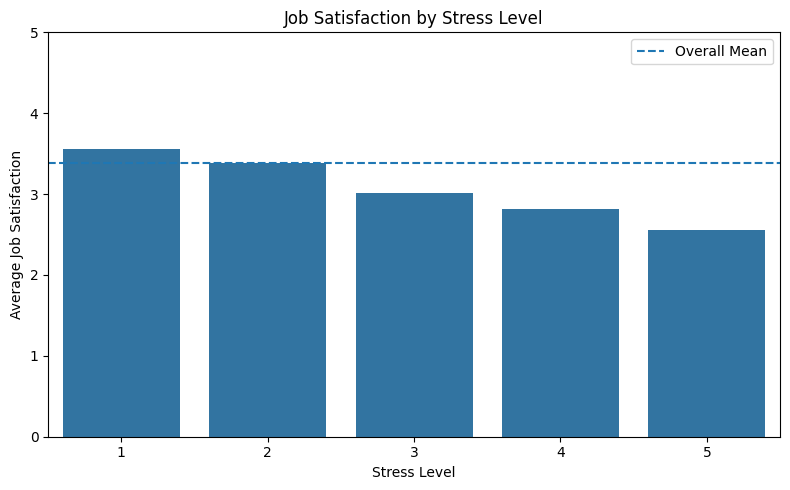

In [ ]:
###Stress
plt.figure(figsize=(8,5))

sns.barplot(
    data=stress_analysis,
    x='stress',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Job Satisfaction by Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.tight_layout()
plt.show()

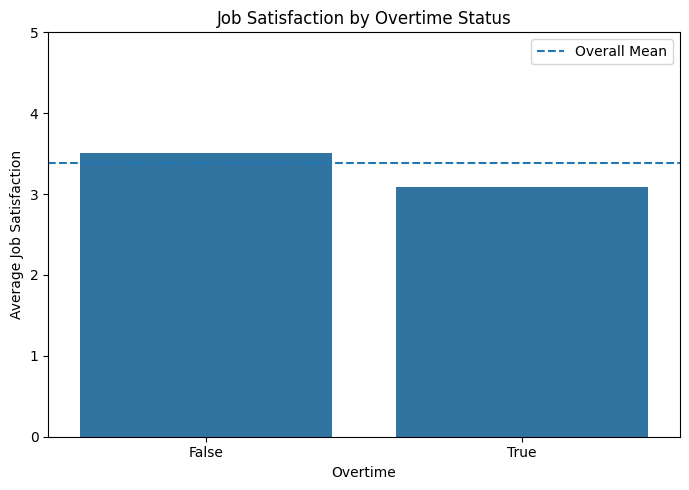

In [ ]:
##Overtime
plt.figure(figsize=(7,5))

sns.barplot(
    data=ot_analysis,
    x='have_ot',
    y='average_satisfaction'
)

plt.axhline(
    df_clean['job_satisfaction'].mean(),
    linestyle='--',
    label='Overall Mean'
)

plt.title('Job Satisfaction by Overtime Status')
plt.xlabel('Overtime')
plt.ylabel('Average Job Satisfaction')
plt.ylim(0,5)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
final_factor_table = pd.DataFrame({
    'Factor': [
        'Workload',
        'Work-Life Balance',
        'Work Environment',
        'Stress',
        'Sleep Hours',
        'Overtime'
    ],
    'Evidence': [
        'Spearman r = -0.252',
        'Spearman r = +0.247',
        'Spearman r = +0.246',
        'Spearman r = -0.191',
        'Spearman r = +0.169',
        'No OT = 3.51 vs OT = 3.09'
    ],
    'Interpretation': [
        'Higher workload is associated with lower job satisfaction',
        'Higher WLB is associated with higher job satisfaction',
        'Better work environment is associated with higher job satisfaction',
        'Higher stress is associated with lower job satisfaction',
        'Higher sleep hours are associated with higher job satisfaction',
        'Employees with overtime have lower average job satisfaction'
    ]
})

final_factor_table

,Factor,Evidence,Interpretation
0,Workload,Spearman r = -0.252,Higher workload is associated with lower job s...
1,Work-Life Balance,Spearman r = +0.247,Higher WLB is associated with higher job satis...
2,Work Environment,Spearman r = +0.246,Better work environment is associated with hig...
3,Stress,Spearman r = -0.191,Higher stress is associated with lower job sat...
4,Sleep Hours,Spearman r = +0.169,Higher sleep hours are associated with higher ...
5,Overtime,No OT = 3.51 vs OT = 3.09,Employees with overtime have lower average job...
